## Intro to OpenCV

In [1]:
# import the necessary packages
import cv2; print('OpenCV version:- ',cv2.__version__)
import numpy as np ; print('numpy version:- ',np.__version__)
from matplotlib import pyplot as plt 

OpenCV version:-  4.6.0
numpy version:-  1.21.6


**Color Images** containing three color channels, represented in a certain way, for example RGB—red, green, blue.

**Grayscale Image** A grayscale image is a black and white image with various shades of gray. The pixel value of a grayscale image is represented as an 8 bit signed integer. i.e values between 0 and 255. The pixel value of the grayscale image represents the brightness of the pixel. The value **0** is **black**, the value **255** is **white**, and the values in between makeup **different shades of gray**.

**Binary Image** A binary image is a black and white image where each pixel value is either 0 or 1. The value **0** represents **background or black** and the value **1** represents **foreground or white**.


********************

### Read image 
* By default opencv read colour image in B,G,R channel format.
* We can read colour image as gray scale (single channel).

In [5]:
image = cv2.imread(r".\data\sample.jpg")
(h, w, d) = image.shape
print("width={}, height={}, depth={}".format(w, h, d),'\n')
cv2.imshow('Colour Image',image)
cv2.waitKey(0)
cv2.destroyAllWindows()

width=1000, height=750, depth=3 



### Load an color image in grayscale

In [6]:
image = cv2.imread(r".\data\sample.jpg",0)
cv2.imshow('Grey scale',image)
cv2.waitKey(0)
cv2.destroyAllWindows()

### Write an image using opencv

In [7]:
image = cv2.imread(r".\data\sample.jpg")
result=cv2.imwrite(r'.\data\sample2.jpg',image)

### Read video using opencv

* We can read video from stored file.
* We can read video from live camera feed also using OpenCV.

#### Reading Videos from local disk

In [8]:
capture = cv2.VideoCapture(r'.\data\sample_video.mp4')
while True:
    isTrue, frame = capture.read()
    if isTrue:    
        cv2.imshow('Video', frame)
        if cv2.waitKey(20) & 0xFF==ord('d'):
            break            
    else:
        break
capture.release()
cv2.destroyAllWindows()

#### Reading Videos from live camera feed

In [9]:
capture = cv2.VideoCapture(0)
while True:
    isTrue, frame = capture.read()
    if isTrue:    
        cv2.imshow('Video', frame)
        if cv2.waitKey(20) & 0xFF==ord('d'):
            break            
    else:
        break
capture.release()
cv2.destroyAllWindows()

*********************

### Basic operations on Images
#### Converting to grayscale

converting colour image to grayscale image.

In [10]:
# Read in an image
img = cv2.imread(r".\data\sample.jpg")
cv2.imshow('sample', img)

# Converting to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
cv2.imshow('Gray', gray)

cv2.waitKey(0)
cv2.destroyAllWindows()

#### Resize image

Most of the SOTA algorithums are based on some fixed size input. In order to process the image using SOTA algorithums, We need to resize the image into particular shape that a model accepts. For an example yolo a well kmown algorithum was trained on image input of 448*448 coloured images.

In [11]:
# Resize
(h, w, d) = img.shape
print("Shape before width={}, height={}, depth={}".format(w, h, d),'\n')
resized = cv2.resize(img, (500,500), interpolation=cv2.INTER_CUBIC)

(h, w, d) = resized.shape
print("Shape After width={}, height={}, depth={}".format(w, h, d))

Shape before width=1000, height=750, depth=3 

Shape After width=500, height=500, depth=3


#### Cropping

Cropping is done to extract the ROI from the image.
For an example in the object detection task if we want to extract the ROI from the image then based on the x-y coordinate space that our algorithum predicts we can crop the image and can save our ROI.

In [12]:
cropped = img[200:400, 400:700]
cv2.imshow('Cropped', cropped)
cv2.waitKey(0)
cv2.destroyAllWindows()

#### Thresholding
* Converting range of pixels into some fixed pixels based on some threshold.
* This is done on colored images in order to do some advance processing on images such as countour detection,
  edge detection etc.

In [15]:
import cv2

img = cv2.imread(r'data\sample.jpg')
cv2.imshow('Sample', img)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Simple Thresholding
threshold, thresh = cv2.threshold(gray, 150, 255, cv2.THRESH_BINARY )
cv2.imshow('Simple Thresholded', thresh)

cv2.waitKey(0)
cv2.destroyAllWindows()

threshold, thresh_inv = cv2.threshold(gray, 150, 255, cv2.THRESH_BINARY_INV )
cv2.imshow('Simple Thresholded Inverse', thresh_inv)

cv2.waitKey(0)
cv2.destroyAllWindows()

#### Draw an object 
* cv2.line(image, startPoint, endPoint, rgb, thinkness)
* cv2.rectangle(image, topLeft, bottomRight, rgb, thinkness)
* cv2.circle(image, center, radius, rgb, thinkness)
* cv2.ellipse(image, center, axes, angle, startAngle, endAngle, rgb, thinkness)

These operations can be done on blank image or on existing image.

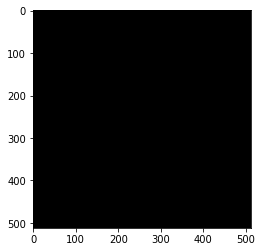

In [16]:
# Create a black image
img2 = np.zeros((512,512,3), np.uint8)
plt.imshow(img2)
plt.show()

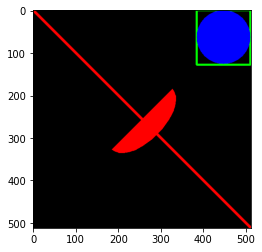

In [17]:
# Draw a line using cv2.line(image, startPoint, endPoint, rgb, thinkness)
cv2.line(img2, (0,0), (511,511), (255,0,0), 5)
# => Diagonal red line with thickness of 5 px

# Draw a rectangle using cv2.rectangle(image, topLeft, bottomRight, rgb, thinkness)
cv2.rectangle(img2, (384,0), (510,128), (0,255,0), 3)
# => Green rectangle with thickness of 3 px

# Draw a circle using cv2.circle(image, center, radius, rgb, thinkness)
cv2.circle(img2, (447,63), 63, (0,0,255), -1)
# => Blue filled circle(note that the thinkness is -1)

# Draw a ellipse using cv2.ellipse(image, center, axes, angle, startAngle, endAngle, rgb, thinkness)
cv2.ellipse(img2, (256,256), (100,50), -45, 0, 180, (255,0,0), -1)
# => Red wide down-half ellipse

plt.imshow(img2)

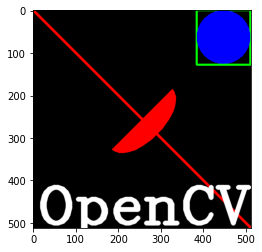

In [18]:
# Put some text using cv2.putText(image, text, bottomLeft, fontType, fontScale, rgb, thinkness, lineType)
font = cv2.FONT_HERSHEY_COMPLEX
cv2.putText(img2, 'OpenCV', (10,500), font, 4, (255,255,255), 10, cv2.LINE_AA)
# => White 'OpenCV' text at the bottom

plt.imshow(img2)
plt.show()

#### Modify pixle of ROI
* You can access/modify a single pixel or ROI using Numpy indexing.
* Just like matrix indexing, img[a, b] refer to a-th row and b-th column.

In [19]:
# Access a pixel value(BGR order)
img[50, 235]

array([210, 149,  63], dtype=uint8)

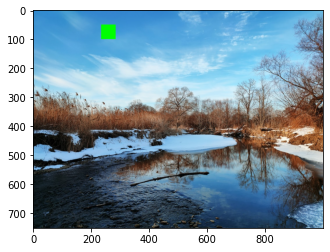

In [20]:
# Change pixel values
for i in range(50):
    for j in range(50):
        img[50+i, 235+j] = (0, 255, 0)
# => Green rectangle at left corner
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

*********************

### Noise

Noise in digital images usually stands for a random variation in the brightness or color of the image.
Any real world sensor is affected by a certain degree of noise, whether it is thermal, electrical or otherwise.

In the case of digital images, noise can be produced due to different reasons:
* The image sensor is broken or affected by external factors;
* Lack of light or overheating of the device at the moment of taking a photo;
* Interference of the transmission channel, and so on.

The noise might be added or multiplied to the image. Here is the formula for the Additive Noise Model, where:

* x and y are the coordinates of the pixel to which the noise is applied;
* s(x, y) is the intensity of the original image;
* n(x, y) is the noise added to the original image;
* w(x,y) is the distorted image received after the noise is applied.


* ***w(x,y) = s(x,y) + n(x,y)***

Likewise, the Multiplicative Noise Model multiplies the original signal by the noise signal.

* ***w(x,y) = s(x,y) X n(x,y)***


Noise may be random or may follow some distribution.

1. For example gaussian Noise is a statistical noise with a Gaussian (normal) distribution. It means that the noise values are distributed in a normal Gaussian way.

2. Salt and pepper noise is an impulse type of noise in images. We consider salt-and-pepper noise, for which a certain amount of the pixels in the image are either black or white (black or white dots). Normally if there is black dots in the image we called it pepper noise and if there is white dots in the image we called it salt noise. This noise is generally caused by errors in data transmission, failure in memory cell or analog-to-digital converter errors.

### Smoothing and blurring

Smoothing and blurring is one of the most important preprocessing steps in all of computer vision and image processing. 
By smoothing an image prior to applying techniques such as edge detection or thresholding we are able to reduce the amount of high-frequency content, such as noise and edges.<br>

While this may sound counter-intuitive, by reducing the detail in an image we can more easily find objects that we are interested in.
Furthermore, this allows us to focus on the larger structural objects in the image.
We’ll be discussing the four main smoothing and blurring options that you’ll often use in your own projects:

* Simple average blurring
* Gaussian blurring
* Median filtering
* Bilateral filtering


#### Average blurring ( cv2.blur )<br>

It takes an area of pixels surrounding a central pixel with the help of kernels, averages all these pixels together, and replaces the central pixel with the average.

By taking the average of the region surrounding a pixel, we are smoothing it and replacing it with the value of its local neighborhood. This allows us to reduce noise and the level of detail, simply by relying on the average.

In [21]:
import cv2
image = cv2.imread(r"data\sample.jpg")
cv2.imshow("Original", image)
kernelSizes = [(3, 3), (9, 9), (15, 15)]
# loop over the kernel sizes
for (kX, kY) in kernelSizes:
    blurred = cv2.blur(image, (kX, kY))
    cv2.imshow("Average ({}, {})".format(kX, kY), blurred)
cv2.waitKey(0)
cv2.destroyAllWindows()

#### Gaussian blurring ( cv2.GaussianBlur)
Gaussian blurring is similar to average blurring, but instead of using a simple mean, we are now using a weighted mean, where neighborhood pixels that are closer to the central pixel contribute more “weight” to the average.

And as the name suggests, Gaussian smoothing is used to remove noise that approximately follows a Gaussian distribution.

The end result is that our image is less blurred, but more “naturally blurred,” than using the average method discussed in the previous section. Furthermore, based on this weighting we’ll be able to preserve more of the edges in our image as compared to average smoothing.

Gaussian smoothing also uses a kernel of M times N, where both M and N are odd integers

In [22]:
import cv2
image = cv2.imread(r"data\rock.jpg")
cv2.imshow("Original", image)
kernelSizes = [(3, 3), (9, 9), (15, 15)]
# loop over the kernel sizes again
for (kX, kY) in kernelSizes:
    # apply a "Gaussian" blur to the image
    blurred = cv2.GaussianBlur(image, (kX, kY), 0)
    cv2.imshow("Gaussian ({}, {})".format(kX, kY), blurred)
cv2.waitKey(0)
cv2.destroyAllWindows()

#### Median blurring ( cv2.medianBlur )

Traditionally, the median blur method has been most effective when removing salt-and-pepper noise. This type of noise is exactly what it sounds like: imagine taking a photograph, putting it on your dining room table, and sprinkling salt and pepper on top of it. Using the median blur method, you could remove the salt and pepper from your image.

When applying a median blur, we first define our kernel size. Then, as in the averaging blurring method, we consider all pixels in the neighborhood of size K \times K where K is an odd integer.

Notice how, unlike average blurring and Gaussian blurring where the kernel size could be rectangular, the kernel size for the median must be square. Furthermore (unlike the averaging method), instead of replacing the central pixel with the average of the neighborhood, we instead replace the central pixel with the median of the neighborhood.

The kernel shape in median blur is square.

In [23]:
image = cv2.imread(r"data\salt_peper.jpg")
cv2.imshow("Original", image)
for k in (3, 9, 15):
    # apply a "median" blur to the image
    blurred = cv2.medianBlur(image, k)
    cv2.imshow("Median {}".format(k), blurred)
cv2.waitKey(0)
cv2.destroyAllWindows()

#### Bilateral blurring ( cv2.bilateralFilter )

The last method we are going to explore is bilateral blurring.

Thus far, the intention of our blurring methods have been to reduce noise and detail in an image; however, as a side effect we have tended to lose edges in the image.

To reduce noise while still maintaining edges, we can use bilateral blurring. Bilateral blurring accomplishes this by introducing two Gaussian distributions.

The first Gaussian function only considers spatial neighbors. That is, pixels that appear close together in the (x, y)-coordinate space of the image. The second Gaussian then models the pixel intensity of the neighborhood, ensuring that only pixels with similar intensity are included in the actual computation of the blur.

Intuitively, this makes sense. If pixels in the same (small) neighborhood have a similar pixel value, then they likely represent the same object. But if two pixels in the same neighborhood have contrasting values, then we could be examining the edge or boundary of an object — and we would like to preserve this edge.

In [24]:
image = cv2.imread(r"data\rock.jpg")
cv2.imshow("Original", image)
params = [(11, 21, 7), (11, 41, 21), (11, 61, 39)]
# loop over the diameter, sigma color, and sigma space
for (diameter, sigmaColor, sigmaSpace) in params:
    # apply bilateral filtering to the image using the current set of
    # parameters
    blurred = cv2.bilateralFilter(image, diameter, sigmaColor, sigmaSpace)
    # show the output image and associated parameters
    title = "Blurred d={}, sc={}, ss={}".format(
        diameter, sigmaColor, sigmaSpace)
    cv2.imshow(title, blurred)
cv2.waitKey(0)
cv2.destroyAllWindows()

**********************

### OpenCV Edge Detection ( cv2.Canny )

**Canny()** function is used to detect the edges in an image.

Canny Edge detection is an Algorithm consisting of 4 major steps:
1. Reduce Noise using Gaussian Smoothing.
2. Computing the gradient magnitude and orientation
3. Non-maxima suppression
4. Hysteresis thresholding

To learn more about the steps involved in canny edge detection:-
https://pyimagesearch.com/2021/05/12/opencv-edge-detection-cv2-canny/

In [28]:
def auto_canny(image, sigma=0.33):
    # compute the median of the single channel pixel intensities
    v = np.median(image)
    # apply automatic Canny edge detection using the computed median
    lower = int(max(0, (1.0 - sigma) * v))
    upper = int(min(255, (1.0 + sigma) * v))
    edged = cv2.Canny(image, lower, upper)
    # return the edged image
    return edged

image = cv2.imread(r"data\cup.jpg")
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (3, 3), 0)
# apply Canny edge detection using a wide threshold, tight
# threshold, and automatically determined threshold
wide = cv2.Canny(blurred, 10, 200)
tight = cv2.Canny(blurred, 225, 250)
auto = auto_canny(blurred)

contours, hierarchies = cv2.findContours(auto, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)

# show the images
cv2.imshow("Original", image)
cv2.imshow("Edges", np.hstack([wide, tight, auto]))

cv2.waitKey(0)
cv2.destroyAllWindows()

### Contour Detection using OpenCV
When we join all the points on the boundary of an object, we get a contour. Typically, a specific contour refers to boundary pixels that have the same color and intensity. OpenCV makes it really easy to find and draw contours in images.

Using contour detection, we can detect the borders of objects, and localize them easily in an image. It is often the first step for many interesting applications, such as image-foreground extraction, simple-image segmentation, detection and recognition. 

In [30]:
import cv2

# Load image, convert to grayscale, and find edges
image = cv2.imread(r"data\contour_sample.jpg")
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (3, 3), 0)
thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_OTSU + cv2.THRESH_BINARY)[1]

# Find contour and sort by contour area
cnts = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cnts = cnts[0] if len(cnts) == 2 else cnts[1]

blank=np.zeros(image.shape, np.uint8)
output = image.copy()
cv2.drawContours(blank, cnts, -1, (0,0,255), 1)
cv2.imshow('Contours Drawn', blank)
cnts = sorted(cnts, key=cv2.contourArea, reverse=True)


# Find bounding box and extract ROI
for c in cnts:
    x,y,w,h = cv2.boundingRect(c)
    ROI = image[y:y+h, x:x+w]
    break

cv2.imshow('Original',output)
cv2.imshow('Original',output)
cv2.imshow('ROI',ROI)
cv2.waitKey()
cv2.destroyAllWindows()

In [33]:
# Another example of contour detection 
import cv2 
# read the image
image = cv2.imread('data/Contour.jpg')
cv2.imshow('Original image', image)

# convert the image to grayscale format
img_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# apply binary thresholding
ret, thresh = cv2.threshold(img_gray, 150, 255, cv2.THRESH_BINARY)

# visualize the binary image
cv2.imshow('Binary image', thresh)

# detect the contours on the binary image using cv2.CHAIN_APPROX_NONE
contours, hierarchy = cv2.findContours(image=thresh, mode=cv2.RETR_TREE, method=cv2.CHAIN_APPROX_NONE)
                                      
# draw contours on the original image
image_copy = image.copy()
cv2.drawContours(image=image_copy, contours=contours, contourIdx=-1, color=(0, 255, 0), thickness=2, lineType=cv2.LINE_AA)
                
# see the results
cv2.imshow('None approximation', image_copy)
cv2.waitKey(0)
cv2.imwrite('data/contours_none_image1.jpg', image_copy)
cv2.destroyAllWindows()